In [1]:
from pathlib import Path
import duckdb


cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd

CSV_PATH = ROOT / "data" / "raw" / "digikala-comments.csv"
DB_PATH = ROOT / "project.duckdb"

print("ROOT:", ROOT)
print("CSV exists:", CSV_PATH.exists())
print("DuckDB version:", duckdb.__version__)

ROOT: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer
CSV exists: True
DuckDB version: 2.0.0


# connecting the DuckDB to Database (Dataset)

In [2]:
con = duckdb.connect(str(DB_PATH))
# con.execute("INSTALL ui;")
con.execute("LOAD ui;")
con.execute("CALL start_ui();")

Opening in existing browser session.


[59627:59627:0100/000000.035970:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)
[1:1:0100/000000.045830:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)


# creating project.duckdb (only once)
### loading all the columns as texts

In [3]:
# con.execute(f"""
#     CREATE OR REPLACE TABLE raw AS
#         SELECT row_number() OVER () AS _row_idx, * FROM read_csv(
#         '{CSV_PATH.as_posix()}',
#         header = true,
#         delim = ',',
#         quote = '"',
#         escape = '"',
#         all_varchar = true
#     )
# """)

In [6]:
con.sql("""
    SELECT COUNT(*) AS n_rows,
           COUNT(DISTINCT id) AS n_unique_ids
    FROM raw
""").show()

con.sql("DESCRIBE raw").show()

┌─────────┬──────────────┐
│ n_rows  │ n_unique_ids │
│  int64  │    int64     │
├─────────┼──────────────┤
│ 6156289 │      6153060 │
└─────────┴──────────────┘

┌───────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │ column_type │  null   │   key   │ default │  extra  │
│        varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id                    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ title                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ body                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ created_at            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rate                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ recommendation_status │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ is_buyer              │ VARCHAR    

# creating two new Tables (run only once):
## defect_manifest
## rule_summary

In [4]:
# con.execute("""
#     CREATE OR REPLACE TABLE defect_manifest (
#         _row_idx BIGINT,
#         id       VARCHAR,
#         rule_id  VARCHAR,
#         field    VARCHAR,
#         action   VARCHAR,
#         evidence VARCHAR
#     )
# """)

# con.execute("""
#     CREATE OR REPLACE TABLE rule_summary (
#         rule_id     VARCHAR,
#         description VARCHAR,
#         action      VARCHAR,
#         n_rows      BIGINT,
#         pct         DOUBLE,
#         reason      VARCHAR
#     )
# """)

In [5]:
con.sql("SELECT _row_idx, id FROM raw ORDER BY _row_idx LIMIT 3").show()
con.sql("SELECT COUNT(*) AS n, MIN(_row_idx) AS lo, MAX(_row_idx) AS hi FROM raw").show()

┌──────────┬──────────┐
│ _row_idx │    id    │
│  int64   │ varchar  │
├──────────┼──────────┤
│        1 │ 53672599 │
│        2 │ 9897229  │
│        3 │ 38074516 │
└──────────┴──────────┘

┌─────────┬───────┬─────────┐
│    n    │  lo   │   hi    │
│  int64  │ int64 │  int64  │
├─────────┼───────┼─────────┤
│ 6156289 │     1 │ 6156289 │
└─────────┴───────┴─────────┘



## creating clean_base (run only once)

In [6]:
# con.execute("""
#     CREATE OR REPLACE TABLE clean_base AS
#     SELECT _row_idx, id, title, body, rate, recommendation_status,
#            product_id, is_buyer, seller_code
#     FROM raw
# """)

# Counting the Missing Values in the columns

In [9]:
cols = ["id", "title", "body", "rate", "recommendation_status",
        "product_id", "is_buyer", "seller_code"]

PLACEHOLDERS = ["null", "nan", "none", "-", "n/a", "na", "undefined"]
ph = ", ".join(f"'{p}'" for p in PLACEHOLDERS)

query = " UNION ALL ".join(f"""
    SELECT '{c}' AS col,
           COUNT(*) FILTER (WHERE {c} IS NULL)                   AS n_null,
           COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$')) AS n_blank,
           COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))    AS n_placeholder,
           COUNT(*) FILTER (WHERE {c} IS NULL)
           + COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$'))
           + COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))  AS n_missing_total
    FROM clean_base
""" for c in cols)

con.sql(query).show()

┌───────────────────────┬────────┬─────────┬───────────────┬─────────────────┐
│          col          │ n_null │ n_blank │ n_placeholder │ n_missing_total │
│        varchar        │ int64  │  int64  │     int64     │      int64      │
├───────────────────────┼────────┼─────────┼───────────────┼─────────────────┤
│ id                    │      0 │       0 │             0 │               0 │
│ title                 │      0 │    1353 │       2865303 │         2866656 │
│ body                  │      0 │       0 │           637 │             637 │
│ rate                  │      0 │       0 │             0 │               0 │
│ recommendation_status │      0 │       0 │        894426 │          894426 │
│ product_id            │      0 │       0 │             0 │               0 │
│ is_buyer              │      0 │       0 │             0 │               0 │
│ seller_code           │      0 │       0 │        302181 │          302181 │
└───────────────────────┴────────┴─────────┴────────

### Placeholder Validation and Missing-Value Inspection

In [10]:
for c in ["title", "body", "recommendation_status", "seller_code"]:
    print(c)
    con.sql(f"""
        SELECT lower(trim({c})) AS value, COUNT(*) AS n
        FROM clean_base
        WHERE lower(trim({c})) IN ({ph}) OR regexp_matches({c}, '^\\s*$')
        GROUP BY 1
        ORDER BY n DESC
    """).show()

con.sql("""
    SELECT recommendation_status, COUNT(*) AS n
    FROM clean_base
    GROUP BY 1
    ORDER BY n DESC
""").show()

title
┌─────────┬─────────┐
│  value  │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ nan     │ 2865062 │
│         │    1353 │
│ -       │     241 │
└─────────┴─────────┘

body
┌─────────┬───────┐
│  value  │   n   │
│ varchar │ int64 │
├─────────┼───────┤
│ nan     │   637 │
└─────────┴───────┘

recommendation_status
┌─────────┬────────┐
│  value  │   n    │
│ varchar │ int64  │
├─────────┼────────┤
│ nan     │ 894426 │
└─────────┴────────┘

seller_code
┌─────────┬────────┐
│  value  │   n    │
│ varchar │ int64  │
├─────────┼────────┤
│ nan     │ 302181 │
└─────────┴────────┘

┌───────────────────────┬─────────┐
│ recommendation_status │    n    │
│        varchar        │  int64  │
├───────────────────────┼─────────┤
│ recommended           │ 4162839 │
│ nan                   │  894426 │
│ no_idea               │  594121 │
│ not_recommended       │  504903 │
└───────────────────────┴─────────┘



# Function for Converting All the missing Values to simple 'null'

### Define

In [13]:
con.execute(f"""
    CREATE OR REPLACE MACRO is_missing(x) AS
        lower(trim(x)) IN ({ph}) OR regexp_matches(x, '^\\s*$')
""")

# how it works:
con.sql("""
    SELECT v, is_missing(v) AS got
    FROM (VALUES ('None'), ('  '), (''), ('-'), ('NaN'),
                 ('عالی'), ('نه'), ('nano'), ('خوب نیست')) AS t(v)
""").show()

┌──────────┬─────────┐
│    v     │   got   │
│ varchar  │ boolean │
├──────────┼─────────┤
│ None     │ true    │
│          │ true    │
│          │ true    │
│ -        │ true    │
│ NaN      │ true    │
│ عالی     │ false   │
│ نه       │ false   │
│ nano     │ false   │
│ خوب نیست │ false   │
└──────────┴─────────┘



### Implement (run only once)

In [ ]:
# N_RAW = con.sql("SELECT COUNT(*) FROM raw").fetchall()[0][0]

# for c in cols:
#     n = con.sql(f"SELECT COUNT(*) FROM clean_base WHERE is_missing({c})").fetchall()[0][0]

#     con.execute(
#         "INSERT INTO rule_summary VALUES (?, ?, ?, ?, ?, ?)",
#         [f"MISS_{c}", f"{c}: missing-like text to NULL", "fix",
#          n, 100 * n / N_RAW, "missing values stored as text; standardized"]
#     )

#     con.execute(f"UPDATE clean_base SET {c} = NULL WHERE is_missing({c})")

In [16]:
con.sql("SELECT * FROM rule_summary ORDER BY n_rows DESC").show()

┌────────────────────────────┬──────────────────────────────────────────────────┬─────────┬─────────┬──────────────────────┬─────────────────────────────────────────────┐
│          rule_id           │                   description                    │ action  │ n_rows  │         pct          │                   reason                    │
│          varchar           │                     varchar                      │ varchar │  int64  │        double        │                   varchar                   │
├────────────────────────────┼──────────────────────────────────────────────────┼─────────┼─────────┼──────────────────────┼─────────────────────────────────────────────┤
│ MISS_title                 │ title: missing-like text to NULL                 │ fix     │ 2866656 │    46.56467556997406 │ missing values stored as text; standardized │
│ MISS_recommendation_status │ recommendation_status: missing-like text to NULL │ fix     │  894426 │   14.528655168722587 │ missing values store

## Now again Counting the Missing Values in the columns

In [17]:
cols = ["id", "title", "body", "rate", "recommendation_status",
        "product_id", "is_buyer", "seller_code"]

PLACEHOLDERS = ["null", "nan", "none", "-", "n/a", "na", "undefined"]
ph = ", ".join(f"'{p}'" for p in PLACEHOLDERS)

query = " UNION ALL ".join(f"""
    SELECT '{c}' AS col,
           COUNT(*) FILTER (WHERE {c} IS NULL)                   AS n_null,
           COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$')) AS n_blank,
           COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))    AS n_placeholder,
           COUNT(*) FILTER (WHERE {c} IS NULL)
           + COUNT(*) FILTER (WHERE regexp_matches({c}, '^\\s*$'))
           + COUNT(*) FILTER (WHERE lower(trim({c})) IN ({ph}))  AS n_missing_total
    FROM clean_base
""" for c in cols)

con.sql(query).show()

┌───────────────────────┬─────────┬─────────┬───────────────┬─────────────────┐
│          col          │ n_null  │ n_blank │ n_placeholder │ n_missing_total │
│        varchar        │  int64  │  int64  │     int64     │      int64      │
├───────────────────────┼─────────┼─────────┼───────────────┼─────────────────┤
│ id                    │       0 │       0 │             0 │               0 │
│ title                 │ 2866656 │       0 │             0 │         2866656 │
│ body                  │     637 │       0 │             0 │             637 │
│ rate                  │       0 │       0 │             0 │               0 │
│ recommendation_status │  894426 │       0 │             0 │          894426 │
│ product_id            │       0 │       0 │             0 │               0 │
│ is_buyer              │       0 │       0 │             0 │               0 │
│ seller_code           │  302181 │       0 │             0 │          302181 │
└───────────────────────┴─────────┴─────

# Now cleaning and checking of the 'recommendation_status' column

## assessing the value distribution

In [18]:
con.sql("""
    SELECT recommendation_status AS value,
           length(recommendation_status) AS len,
           COUNT(*) AS n
    FROM clean_base
    GROUP BY 1, 2
    ORDER BY n DESC
""").show()

┌─────────────────┬───────┬─────────┐
│      value      │  len  │    n    │
│     varchar     │ int64 │  int64  │
├─────────────────┼───────┼─────────┤
│ recommended     │    11 │ 4162839 │
│ NULL            │  NULL │  894426 │
│ no_idea         │     7 │  594121 │
│ not_recommended │    15 │  504903 │
└─────────────────┴───────┴─────────┘



### Recommendation_Status Vocabulary Validation

In [20]:
n_unknown = con.sql("""
    SELECT COUNT(*) FROM clean_base
    WHERE recommendation_status IS NOT NULL
      AND recommendation_status NOT IN ('recommended', 'no_idea', 'not_recommended')
""").fetchall()[0][0]

assert n_unknown == 0

# registring in rule_summary table

con.execute(
    "INSERT INTO rule_summary VALUES (?, ?, ?, ?, ?, ?)",
    ["LABEL_rec_vocab", "recommendation_status has only the 3 valid values",
     "check", n_unknown, 100 * n_unknown / N_RAW, "no mapping needed"]
)

# Now cleaning and checking of the 'rating' column

### 1- which are not numbers, 2- rate domain, 3- most frequent

In [27]:
# 1) Values that cannot be interpreted as numbers
con.sql("""
    SELECT rate AS value, COUNT(*) AS n
    FROM clean_base
    WHERE TRY_CAST(rate AS DOUBLE) IS NULL
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 30
""").show()

# 2) Minimum and maximum numeric values, and the number of distinct values
con.sql("""
    SELECT MIN(TRY_CAST(rate AS DOUBLE)) AS min_rate,
           MAX(TRY_CAST(rate AS DOUBLE)) AS max_rate,
           COUNT(DISTINCT rate)          AS n_distinct
    FROM clean_base
""").show()

# 3) Most frequent values
con.sql("""
    SELECT rate AS value, COUNT(*) AS n
    FROM clean_base
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 15
""").show()

┌─────────┬───────┐
│  value  │   n   │
│ varchar │ int64 │
└─────────┴───────┘
      0 rows     

┌──────────┬──────────┬────────────┐
│ min_rate │ max_rate │ n_distinct │
│  double  │  double  │   int64    │
├──────────┼──────────┼────────────┤
│      0.0 │   2500.0 │        178 │
└──────────┴──────────┴────────────┘

┌─────────┬─────────┐
│  value  │    n    │
│ varchar │  int64  │
├─────────┼─────────┤
│ 5.0     │ 2398801 │
│ 4.0     │ 1515723 │
│ 3.0     │  958799 │
│ 0.0     │  529098 │
│ 1.0     │  327662 │
│ 2.0     │  198077 │
│ 4.5     │   13479 │
│ 3.5     │   12207 │
│ 4.25    │   11653 │
│ 3.75    │   10045 │
│ 4.2     │    9843 │
│ 3.8     │    8745 │
│ 4.4     │    8675 │
│ 4.75    │    8292 │
│ 4.6     │    8152 │
└─────────┴─────────┘
       15 rows     



### Converting the str to decimal vlaues in rating and Creating rating_bands

In [32]:
# Shared SQL expression for "the cleaned rate": 2 decimals, or NULL if unusable.
# Used by the guard, the manifest and the column conversion, so all three agree.
RATE_CLEAN = """
    CASE WHEN TRY_CAST(rate AS DECIMAL(10,2)) BETWEEN 0 AND 5
         THEN TRY_CAST(rate AS DECIMAL(10,2))
    END
"""

# 1) Guard: 2-decimal rounding must not change any valid value.
#    Runs BEFORE the overwrite, while the original text values still exist.
n_rounded = con.sql(f"""
    SELECT COUNT(*) FROM clean_base
    WHERE ({RATE_CLEAN}) IS NOT NULL
      AND CAST(({RATE_CLEAN}) AS DOUBLE) <> TRY_CAST(rate AS DOUBLE)
""").fetchall()[0][0]
assert n_rounded == 0, f"{n_rounded} rate values have more than 2 decimals"

# 2) Log every unusable rate (the row is kept) in the manifest.
#    Evidence is the ORIGINAL value, so this must run before the overwrite.
con.execute(f"""
    INSERT INTO defect_manifest
    SELECT _row_idx, id, 'RATE_invalid', 'rate', 'flag', rate
    FROM clean_base
    WHERE ({RATE_CLEAN}) IS NULL
""")
n_invalid = con.sql(
    "SELECT COUNT(*) FROM defect_manifest WHERE rule_id = 'RATE_invalid'"
).fetchall()[0][0]

con.execute(
    "INSERT INTO rule_summary VALUES (?, ?, ?, ?, ?, ?)",
    ["RATE_invalid", "rate missing, non-numeric or outside 0..5",
     "flag", n_invalid, 100 * n_invalid / N_RAW,
     "row kept; only rating_band is invalid for it"]
)

# 3) Overwrite rate in place: same name, same position, DECIMAL(10,2).
#    Unusable values become NULL through the same RATE_CLEAN expression.
con.execute(f"""
    ALTER TABLE clean_base
    ALTER COLUMN rate SET DATA TYPE DECIMAL(10,2)
    USING ({RATE_CLEAN})
""")

# Sanity check: NULLs in rate must match the logged invalid rows exactly.
n_null = con.sql("SELECT COUNT(*) FROM clean_base WHERE rate IS NULL").fetchall()[0][0]
assert n_null == n_invalid, "rate NULL count does not match the defect manifest"

# 4) Add rating_band to clean_base and fill it from the cleaned rate.
con.execute("ALTER TABLE clean_base ADD COLUMN rating_band VARCHAR")
con.execute("""
    UPDATE clean_base
    SET rating_band = CASE
        WHEN rate IS NULL THEN NULL
        WHEN rate < 2.5   THEN 'low'
        WHEN rate < 4.0   THEN 'medium'
        ELSE 'high'
    END
""")

# 5) Look at the result. The NULL group is the number of invalid rows.
con.sql("""
    SELECT rating_band, COUNT(*) AS n
    FROM clean_base
    GROUP BY 1
    ORDER BY n DESC
""").show()

con.sql("""
    SELECT evidence AS invalid_rate, COUNT(*) AS n
    FROM defect_manifest
    WHERE rule_id = 'RATE_invalid'
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 20
""").show()

┌─────────────┬─────────┐
│ rating_band │    n    │
│   varchar   │  int64  │
├─────────────┼─────────┤
│ high        │ 4004905 │
│ low         │ 1092329 │
│ medium      │ 1059054 │
│ NULL        │       1 │
└─────────────┴─────────┘

┌──────────────┬───────┐
│ invalid_rate │   n   │
│   varchar    │ int64 │
├──────────────┼───────┤
│ NULL         │     1 │
└──────────────┴───────┘



# controlling the Rate and rating_band column and save a report

### for rate Column:

Figures folder: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures
rate range: [0.00, 5.00]
rate column type(s): [('DECIMAL(10,2)', 6156289)]
┌────────────┬─────────┐
│ value_kind │    n    │
│  varchar   │  int64  │
├────────────┼─────────┤
│ number     │ 6156288 │
│ NULL       │       1 │
└────────────┴─────────┘

rate NULL rows: 1 of 6,156,289 (0.00%)
curve min: 0.01%, curve max: 26.63% (must be within 0..100)


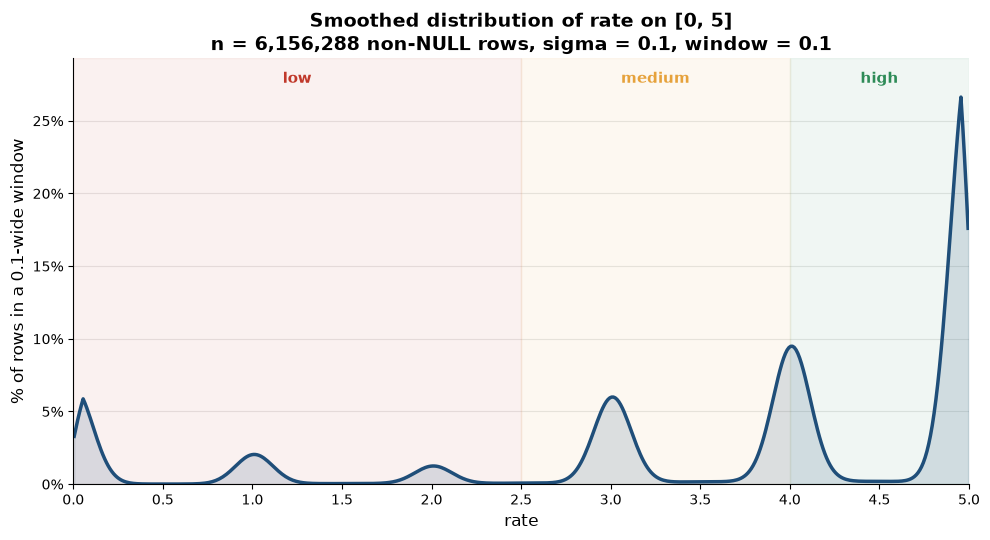

Saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/rate_distribution_curve.png


In [42]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.ndimage import gaussian_filter1d, uniform_filter1d

# ---------------- Parameters (edit here) ----------------
PROJECT_ROOT = None          # None = auto-detect the folder that contains "notebooks/"
RATE_MIN, RATE_MAX = 0.0, 5.0
FINE_BIN_WIDTH = 0.01        # histogram bin width in rate units (rate has 2 decimals)
SMOOTH_SIGMA = 0.10          # Gaussian smoothing width in rate units (larger = smoother)
RATE_WINDOW = 0.10           # width of the window in which the % of rows is counted
Y_MIN_PCT = 0.0              # lower limit of the vertical axis, in %
Y_MAX_PCT = None             # upper limit of the vertical axis, in %; None = automatic
BAND_EDGES = (2.5, 4.0)      # rating_band thresholds (used for background shading only)
FIG_NAME = "rate_distribution_curve.png"
DPI = 200
BAND_COLORS = {"low": "#c0392b", "medium": "#e6a23c", "high": "#2e8b57"}
# ---------------------------------------------------------

# Resolve the project root (the folder that contains notebooks/)
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir()),
        None,
    )
    assert PROJECT_ROOT is not None, "Project root not found; set PROJECT_ROOT manually."
FIG_DIR = Path(PROJECT_ROOT) / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Figures folder:", FIG_DIR.resolve())

N_FINE = round((RATE_MAX - RATE_MIN) / FINE_BIN_WIDTH)

# 1) Range of rate (expected [0.00, 5.00])
lo, hi = con.sql("SELECT MIN(rate), MAX(rate) FROM clean_base").fetchall()[0]
print(f"rate range: [{lo}, {hi}]")
assert float(lo) >= RATE_MIN and float(hi) <= RATE_MAX, "rate is outside the expected range"

# 2) Data type of the column (expected: one type, DECIMAL)
type_rows = con.sql("SELECT typeof(rate), COUNT(*) FROM clean_base GROUP BY 1").fetchall()
print("rate column type(s):", type_rows)
assert len(type_rows) == 1 and type_rows[0][0].startswith("DECIMAL"), "rate has mixed types"

# 3) Value kinds: every row is either NULL or a number
con.sql("""
    SELECT CASE WHEN rate IS NULL THEN 'NULL' ELSE 'number' END AS value_kind,
           COUNT(*) AS n
    FROM clean_base
    GROUP BY 1
    ORDER BY n DESC
""").show()

# 4) NULL count and share
n_total, n_null = con.sql(
    "SELECT COUNT(*), COUNT(*) - COUNT(rate) FROM clean_base"
).fetchall()[0]
print(f"rate NULL rows: {n_null:,} of {n_total:,} ({100 * n_null / n_total:.2f}%)")

# 5) Histogram on fine bins, computed inside DuckDB.
#    The epsilon protects FLOOR from float error, e.g. 0.29 / 0.01 = 28.999999999999996.
hist = con.sql(f"""
    SELECT CAST(LEAST(
               FLOOR((CAST(rate AS DOUBLE) - {RATE_MIN}) / {FINE_BIN_WIDTH} + 1e-9),
               {N_FINE - 1}) AS INTEGER) AS bin_idx,
           COUNT(*) AS n
    FROM clean_base
    WHERE rate BETWEEN {RATE_MIN} AND {RATE_MAX}
    GROUP BY 1
""").fetchnumpy()

counts = np.zeros(N_FINE)
counts[hist["bin_idx"]] = hist["n"]
n_valid = counts.sum()

# 6) Smooth the histogram with a Gaussian kernel.
#    share[i] = fraction of all rows in fine bin i (the shares sum to 1).
sigma_bins = SMOOTH_SIGMA / FINE_BIN_WIDTH
smoothed = gaussian_filter1d(counts, sigma=sigma_bins, mode="reflect")
smoothed *= n_valid / smoothed.sum()          # keep the total equal to n_valid
share = smoothed / n_valid

# 7) At each point, add up the shares inside a window of width RATE_WINDOW centred there.
#    Each bin is counted at most once, so the value always lies between 0 and 100 %.
window_bins = max(1, round(RATE_WINDOW / FINE_BIN_WIDTH))
y_pct = 100 * uniform_filter1d(share, size=window_bins, mode="constant") * window_bins
x = RATE_MIN + (np.arange(N_FINE) + 0.5) * FINE_BIN_WIDTH

# Control: every value must lie between 0 and 100
print(f"curve min: {y_pct.min():.2f}%, curve max: {y_pct.max():.2f}% (must be within 0..100)")
assert 0 <= y_pct.min() and y_pct.max() <= 100, "curve value outside 0..100"

fig, ax = plt.subplots(figsize=(10, 5.5))

# Light background bands for the three rating_band classes
ax.axvspan(RATE_MIN, BAND_EDGES[0], color=BAND_COLORS["low"], alpha=0.07)
ax.axvspan(BAND_EDGES[0], BAND_EDGES[1], color=BAND_COLORS["medium"], alpha=0.07)
ax.axvspan(BAND_EDGES[1], RATE_MAX, color=BAND_COLORS["high"], alpha=0.07)

# Smooth curve with a light area under it
ax.plot(x, y_pct, color="#1f4e79", linewidth=2.5)
ax.fill_between(x, y_pct, color="#1f4e79", alpha=0.15)

# Vertical axis limits from parameters
y_top = Y_MAX_PCT if Y_MAX_PCT is not None else y_pct.max() * 1.1
ax.set_ylim(Y_MIN_PCT, y_top)

# Class names at the top of each background band
band_mids = [
    ("low", (RATE_MIN + BAND_EDGES[0]) / 2),
    ("medium", (BAND_EDGES[0] + BAND_EDGES[1]) / 2),
    ("high", (BAND_EDGES[1] + RATE_MAX) / 2),
]
for label, x_mid in band_mids:
    ax.text(x_mid, y_top * 0.97, label, ha="center", va="top",
            color=BAND_COLORS[label], fontsize=11, fontweight="bold")

ax.set_xlim(RATE_MIN, RATE_MAX)
ax.set_xticks(np.arange(RATE_MIN, RATE_MAX + 1e-9, 0.5))
ax.set_xlabel("rate", fontsize=12)
ax.set_ylabel(f"% of rows in a {RATE_WINDOW:g}-wide window", fontsize=12)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_title(
    f"Smoothed distribution of rate on [{RATE_MIN:g}, {RATE_MAX:g}]\n"
    f"n = {int(n_valid):,} non-NULL rows, sigma = {SMOOTH_SIGMA:g}, window = {RATE_WINDOW:g}",
    fontsize=14, fontweight="bold",
)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()

out_curve = FIG_DIR / FIG_NAME
fig.savefig(out_curve, dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved:", out_curve.resolve())

### for rating_band Column

Figures folder: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures
rating_band NULL rows: 1 of 6,156,289 (0.00%)
rating_band column type(s): [('VARCHAR', 6156289)]
   low:    1,092,329  (17.74%)
medium:    1,059,054  (17.20%)
  high:    4,004,905  (65.05%)


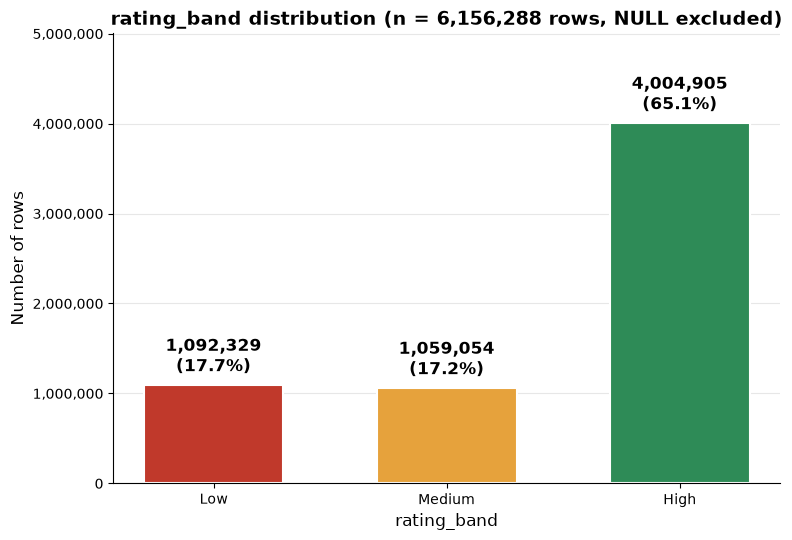

Saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/figures/rating_band_distribution.png


In [41]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------------- Parameters (edit here) ----------------
PROJECT_ROOT = None          # None = auto-detect the folder that contains "notebooks/"
CLASSES = ["low", "medium", "high"]
BAND_COLORS = {"low": "#c0392b", "medium": "#e6a23c", "high": "#2e8b57"}
FIG_NAME = "rating_band_distribution.png"
DPI = 200
# ---------------------------------------------------------

# Resolve the project root (the folder that contains notebooks/)
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir()),
        None,
    )
    assert PROJECT_ROOT is not None, "Project root not found; set PROJECT_ROOT manually."
FIG_DIR = Path(PROJECT_ROOT) / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Figures folder:", FIG_DIR.resolve())

# 1) NULL rows and data type
n_total, n_null = con.sql(
    "SELECT COUNT(*), COUNT(*) - COUNT(rating_band) FROM clean_base"
).fetchall()[0]
print(f"rating_band NULL rows: {n_null:,} of {n_total:,} ({100 * n_null / n_total:.2f}%)")

type_rows = con.sql("SELECT typeof(rating_band), COUNT(*) FROM clean_base GROUP BY 1").fetchall()
print("rating_band column type(s):", type_rows)
assert len(type_rows) == 1 and type_rows[0][0] == "VARCHAR", "rating_band has unexpected type"

# 2) Count and share of each class (NULL excluded, so shares add up to 100%)
class_rows = con.sql("""
    SELECT rating_band, COUNT(*) AS n
    FROM clean_base
    WHERE rating_band IS NOT NULL
    GROUP BY 1
""").fetchall()
class_counts = dict(class_rows)
assert set(class_counts) <= set(CLASSES), f"unexpected labels: {set(class_counts) - set(CLASSES)}"

ordered = [class_counts.get(c, 0) for c in CLASSES]
total_valid = sum(ordered)
percents = [100 * n / total_valid for n in ordered]
for c, n, p in zip(CLASSES, ordered, percents):
    print(f"{c:>6}: {n:>12,}  ({p:.2f}%)")

# 3) Bar chart with count and percentage above each bar
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(
    [c.capitalize() for c in CLASSES], ordered,
    color=[BAND_COLORS[c] for c in CLASSES],
    width=0.6, edgecolor="white", linewidth=1.5,
)
for bar, n, p in zip(bars, ordered, percents):
    ax.annotate(
        f"{n:,}\n({p:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6), textcoords="offset points",
        ha="center", va="bottom", fontsize=12, fontweight="bold",
    )
ax.set_ylim(0, max(ordered) * 1.25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("rating_band", fontsize=12)
ax.set_ylabel("Number of rows", fontsize=12)
ax.set_title(
    f"rating_band distribution (n = {total_valid:,} rows, NULL excluded)",
    fontsize=14, fontweight="bold",
)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()

out_bar = FIG_DIR / FIG_NAME
fig.savefig(out_bar, dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved:", out_bar.resolve())